# Experimental setup and regions of interest

<div class="alert alert-warning">

**Experimental:** Regions of interest work, but the API may change and
they are not yet integrated with the other methods (e.g., there is no
method that returns the time spent in a region per trial).

</div>

Gaze positions are recorded in screen pixels. To relate them to what was
on the screen, or to express them in mm or degrees of visual angle,
`pypillometry` needs the geometry of the setup. Regions of interest (ROIs)
then mark parts of the screen, e.g., where stimuli were shown.

In [1]:
import pypillometry as pp
from pypillometry import u
import numpy as np
import matplotlib.pyplot as plt

pp.logging_set_level("WARNING")

d = pp.get_example_data("rlmw_002_short")

## The experimental setup

The geometry is stored in `d.experimental_setup`. For Eyelink files, the
screen resolution is read from the file; the example dataset also has
the physical screen size and the distance from the eye to the screen:

In [2]:
d.experimental_setup

ExperimentalSetup(
  screen=1280x1024px
  physical=300x200mm
  d=600mm
)

Missing values are set (or changed) with `set_experimental_setup()`.
Lengths and angles take units:

```python
d.set_experimental_setup(physical_screen_size=("30 cm", "20 cm"),
                         eye_to_screen_center=60 * u.cm)
```

With this information, the setup converts between pixels, mm (relative to
the screen center, y up) and degrees of visual angle:

In [3]:
setup = d.experimental_setup
print(setup.pixels_to_degrees(1280, 512))   # right edge, middle
print(setup.degrees_to_pixels(-8, 0))       # 8 degrees left of the center

(np.float64(14.036243467926479), np.float64(0.0))
(np.float64(280.2154631618779), np.float64(512.0))


It also defines the screen boundaries, which are used, e.g., by
`mask_offscreen_coords()` to mask samples outside the screen.

## Where did the participant look?

In this task, two stimuli were shown to the left and right of the screen
center. A heatmap of the gaze positions of the left eye shows them as two
clusters next to the central fixation point:

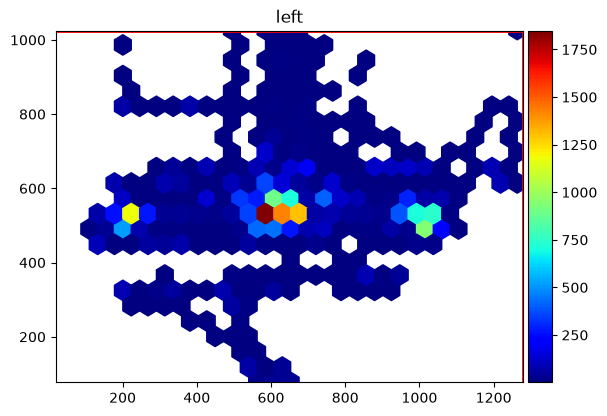

In [4]:
d.plot.plot_heatmap(eyes="left")

## Defining regions of interest

ROIs are circles (`CircularROI`) or rectangles (`RectangularROI`). They
are stored in pixels, but can be created from mm or degrees with
`from_mm()` and `from_degrees()`. Here, two circles with a radius of 3°,
8° to the left and right of the center:

In [5]:
left_roi = pp.CircularROI.from_degrees(("-8 deg", "0 deg"), "3 deg",
                                       setup=setup, name="left stimulus")
right_roi = pp.CircularROI.from_degrees(("8 deg", "0 deg"), "3 deg",
                                        setup=setup, name="right stimulus")
left_roi, right_roi

(CircularROI(name=left stimulus)(center=[280.21546316 512.        ], radius=146.36063450682056),
 CircularROI(name=right stimulus)(center=[999.78453684 512.        ], radius=146.36063450682056))

`plot_heatmap()` shows ROIs on top of the data:

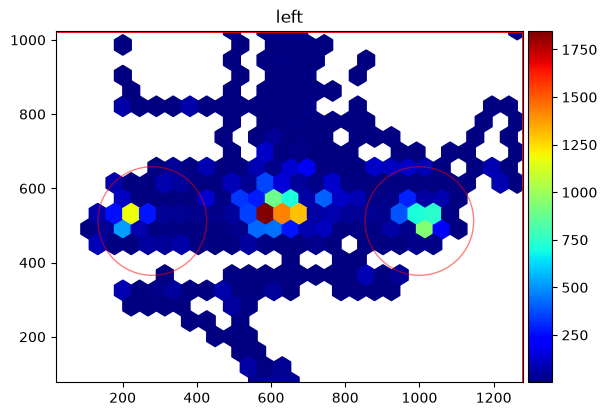

In [6]:
d.plot.plot_heatmap(eyes="left", rois=[left_roi, right_roi])

## Which samples are in a region?

`contains()` takes an array of (x, y) positions and returns `True` for
those inside the region. For single points, `in` works as well:

In [7]:
print((280, 512) in left_roi)

gaze = np.column_stack([d["left_x"], d["left_y"]])
in_left = left_roi.contains(gaze)
in_right = right_roi.contains(gaze)
print(f"left: {in_left.mean():.1%}, right: {in_right.mean():.1%} of samples")

True
left: 14.6%, right: 18.7% of samples


## Combining ROIs with intervals and events

The result is a boolean array with one value per sample, so it can be
converted to [intervals](../notebooks/intervals.ipynb): the periods in
which the participant looked at the left stimulus. Very short visits are
removed with `filter()`:

In [8]:
visits = pp.Intervals.from_mask(in_left, units="ms", sampling_rate=d.fs,
                                label="left stimulus")
visits = visits.filter(min_duration=100 * u.ms)
visits

Intervals 'left stimulus' | 18 intervals (total duration: 5768.00 ms), 320.44 ms +/- 163.24 ms, [166.00 ms, 844.00 ms] | fs=500.0Hz

To get the proportion of time spent on the left stimulus after each
stimulus onset, we store the boolean array as a new variable and use
`stat_per_event()`:

In [9]:
d["left", "in_left_roi"] = in_left.astype(float)
props = d.stat_per_event(interval=(0, 1000) * u.ms, event_select="S_",
                         eyes="left", variables="in_left_roi")
props["left_in_left_roi"]

array([0.418, 0.398, 0.476, 0.494, 0.25 , 0.366, 0.248, 0.384, 0.342,
       0.412])